# La batería de validación sobre una escalera de modelos: discriminación, calibración y estabilidad

**Pregunta:** Cuando la misma batería de pruebas se ejecuta sobre toda la escalera de modelos, ¿qué familia de pruebas detecta qué tipo de problema (orden, nivel, ajuste o estabilidad de la población), y dónde falla en otra un modelo que luce sano en una familia?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 y 02 de este tema, y el notebook 04 del tema 01
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- leer la batería versionada de C01, 187 filas de prueba sobre ocho modelos, como una sola tabla, y decir qué pruebas llevan umbral y cuáles solo describen;
- llamar a las pruebas de discriminación, calibración y estabilidad del motor sobre las tarjetas, los grados y los tramos de confiabilidad versionados, y leer la luz que da cada una;
- abrir la prueba de Hosmer-Lemeshow sobre diez tramos de confiabilidad y leer el diagrama de confiabilidad que resume;
- ver qué pruebas notan una deriva de las entradas y cuáles un cambio de la tasa de incumplimiento, y por qué un modelo puede estar en verde en una familia y en ámbar en otra.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation.calibration import pd_brier, pd_chi2_grades, pd_ece, pd_hosmer_lemeshow
from riskvalidation.validation.calibration import pd_jeffreys, pd_jeffreys_grades, pd_spiegelhalter, pd_traffic_lights
from riskvalidation.validation.discrimination import disc_auc_vs_initial, disc_delong
from riskvalidation.validation.stability import psi_benchmark

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso es otra vez C01: las 9.000 tarjetas reservadas de Taiwán puntuadas por los ocho modelos de la escalera (archivo de tarjetas de crédito de Taiwán de UCI, Yeh, 2009; dueño: UCI Machine Learning Repository; CC BY 4.0, clase de licencia `mirror-allowed`; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). Tres archivos versionados contienen la batería:

- `data/derived/C01/holdout.json`: la escalera, la batería (`tests`, una fila por prueba, modelo y segmento) y, por modelo, la tabla de grados, los tramos de confiabilidad y la ROC; más una muestra de 50 tarjetas puntuadas por dos modelos.
- `data/derived/C01/drift-moderate.json` y `data/derived/C01/prior-shift.json`: los mismos modelos y la misma batería sobre las mismas tarjetas tras una **perturbación sintética solo del conjunto de evaluación** (una deriva moderada de las entradas, una tasa de incumplimiento multiplicada por 1,5). Los modelos no se reajustan; la perturbación es un esfuerzo para las pruebas, no datos.

La siguiente celda carga los tres archivos e imprime el tamaño de cada conjunto de evaluación.

In [2]:
# Cargar las tres baterías versionadas del caso C01 (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))
drift = json.loads((derived / "drift-moderate.json").read_text(encoding="utf-8"))
prior = json.loads((derived / "prior-shift.json").read_text(encoding="utf-8"))
tests = holdout["tests"]
rungs = holdout["outputs"]["rungs"]
ladder = [m["id"] for m in holdout["model"]]
sample = holdout["outputs"]["sample"]
policy = rv.default_policy()
LIGHT = {"green": "verde", "amber": "ámbar", "red": "roja", "not_evaluated": "ninguna"}
print("modelos:", ladder)
for name, doc in zip(["muestra reservada", "deriva", "cambio de tasa"], (holdout, drift, prior)):
    out = doc["outputs"]
    print("conjuntos de evaluación, tarjetas e incumplimientos:", name, out["n"], out["defaults"], len(doc["tests"]))
print("calculado por riskvalidation", holdout["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

modelos: ['P0-constant', 'P0-single', 'P1-scorecard', 'P2a-l1', 'P2b-pltr', 'P3-ebm', 'P4-lightgbm', 'P4-xgboost']
conjuntos de evaluación, tarjetas e incumplimientos: muestra reservada 9000 1991 187
conjuntos de evaluación, tarjetas e incumplimientos: deriva 9000 2316 186
conjuntos de evaluación, tarjetas e incumplimientos: cambio de tasa 9000 2986 186
calculado por riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: una tabla de pruebas, tres tipos de fila

Cada fila de `tests` es un `TestResult` del motor: un identificador de prueba, un modelo, un segmento, el estadístico, el valor p o la métrica, y la luz que le dio la política. El **segmento** dice de qué trata la fila: `portfolio` para toda la muestra reservada, un grado (`G05`, `G06` y así sucesivamente) para las tarjetas de un grado, y `characteristic:<nombre>` para una variable de entrada de las pruebas de estabilidad. La **política** decide qué pruebas tienen luz. Una prueba con umbral se pinta desde su valor p (ámbar bajo 0,05, roja bajo 0,01 en la política por defecto); una prueba descriptiva (AUC, KS, Brier, ECE) mide y no recibe luz, porque las instrucciones del BCE y el documento de trabajo que las respalda no dan umbral para ella. La celda cuenta las filas versionadas de los ocho modelos por prueba y por tipo de segmento.

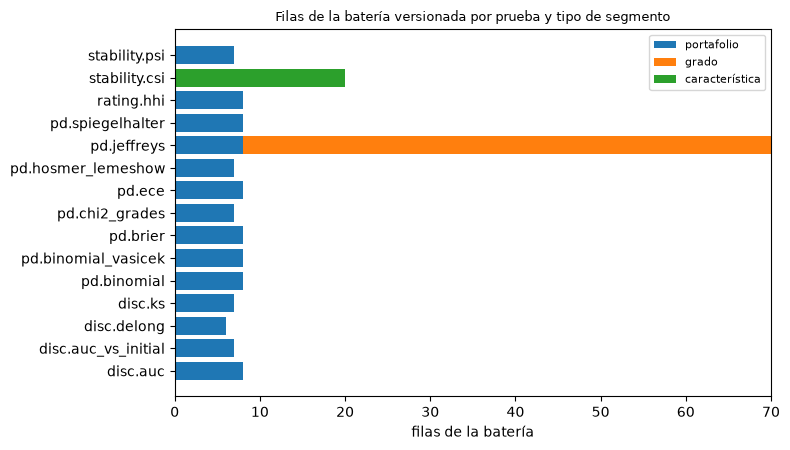

pruebas con umbral en la política por defecto: 11 de 15
filas en total: 187
filas por tipo (portafolio, grado, característica): [105  62  20]


In [3]:
# Contar las filas versionadas por prueba y tipo de segmento, y las pruebas que llevan umbral
ids = sorted({t["test_id"] for t in tests})
counts = np.zeros((len(ids), 3), dtype=int)
for t in tests:
    s = t["segment"]
    k = 0 if s == "portfolio" else (2 if s.startswith("characteristic:") else 1)
    counts[ids.index(t["test_id"]), k] += 1
fig, ax = plt.subplots(figsize=(8, 4.6))
left = np.zeros(len(ids))
for k, label in enumerate(["portafolio", "grado", "característica"]):
    ax.barh(ids, counts[:, k], left=left, label=label)
    left += counts[:, k]
ax.set_xlabel("filas de la batería")
ax.set_title("Filas de la batería versionada por prueba y tipo de segmento", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
with_threshold = sum(i in policy.thresholds for i in ids)
print("pruebas con umbral en la política por defecto:", with_threshold, "de", len(ids))
print("filas en total:", len(tests))
print("filas por tipo (portafolio, grado, característica):", counts.sum(axis=0))

Hay 187 filas, 105 a nivel de portafolio, 62 a nivel de grado (la prueba de Jeffreys de cada grado) y 20 de estabilidad por característica de las entradas, en 15 identificadores de prueba, 11 de los cuales llevan umbral. La figura muestra también el peso de cada familia: las pruebas de nivel y de ajuste dominan la cuenta, la discriminación aparece una vez por modelo, y la estabilidad son las 20 filas de variables más una fila de población. Lo que la cuenta no muestra es si una fila es informativa. Una fila gris, descriptiva, nunca puede poner en rojo a un modelo, así que leer una batería solo por sus luces ignora por diseño el AUC y el KS.

### Paso 2: discriminación, las pruebas que comparan modelos

La primera familia pregunta si la PD ordena a los incumplidores sobre los buenos pagadores. El AUC es descriptivo. La **prueba de DeLong** (DeLong, DeLong y Clarke-Pearson, 1988) compara el AUC de dos modelos puntuados sobre las mismas tarjetas, cuyas estimaciones están correlacionadas, con $z = (\widehat{\mathrm{AUC}}_1 - \widehat{\mathrm{AUC}}_2)/\sqrt{\widehat{\mathrm{Var}}(\widehat{\mathrm{AUC}}_1 - \widehat{\mathrm{AUC}}_2)}$ y un valor p de dos colas sobre una normal estándar. El **AUC contra desarrollo** pregunta si el AUC de ahora cayó bajo el que se midió cuando se construyó el modelo, una pregunta de una cola. La celda llama a ambas sobre la muestra de 50 tarjetas, donde dos modelos están puntuados sobre las mismas tarjetas: la máquina de refuerzo explicable contra la tarjeta de puntaje, y la tarjeta de puntaje contra su AUC de desarrollo con la varianza que guarda la fila versionada.

In [4]:
# Pruebas de discriminación del motor en las 50 tarjetas: DeLong entre dos modelos y AUC contra desarrollo
y50 = np.array(sample["targets"])
pd50 = np.array(sample["scorecard_pd"])
ebm50 = np.array(sample["ebm_logit"])
duo = disc_delong(ebm50, pd50, y50, policy=policy, model_id="P3-ebm")
dev = next(t for t in tests if t["test_id"] == "disc.auc_vs_initial" and t["model_id"] == "P1-scorecard")
e = dev["extras"]
small = disc_auc_vs_initial(e["auc_initial"], pd50, y50, auc_initial_variance=e["auc_initial_variance"],
                            policy=policy, model_id="P1-scorecard")
print("DeLong en 50 tarjetas, EBM contra tarjeta de puntaje: z y p:", round(duo.statistic, 2), round(duo.p_value, 3))
print("AUC contra desarrollo en 50 tarjetas: p y luz:", round(small.p_value, 4), LIGHT[small.light.value])

DeLong en 50 tarjetas, EBM contra tarjeta de puntaje: z y p: -0.17 0.866
AUC contra desarrollo en 50 tarjetas: p y luz: 0.5476 verde


En 50 tarjetas el motor no encuentra diferencia entre la máquina de refuerzo explicable y la tarjeta de puntaje (z de -0,17, p de 0,866), y el AUC de la tarjeta de puntaje no está bajo su AUC de desarrollo (p de 0,5476, verde). Nada de esto es evidencia de equivalencia: con 15 incumplidores, una prueba que no rechaza dice solo que la muestra es demasiado pequeña para distinguir. Las mismas pruebas en 9.000 tarjetas son las que la batería versiona, y la siguiente celda las dibuja.

### Paso 3: los ocho modelos en las 9.000 tarjetas reservadas

Las filas de AUC versionadas llevan un intervalo de 95%, y las filas de DeLong comparan a cada retador con la tarjeta de puntaje sobre las mismas 9.000 tarjetas. La figura dibuja el AUC de los ocho peldaños con su intervalo, con una línea punteada en el valor de la tarjeta de puntaje, y la celda imprime el AUC de cada modelo y el valor p de DeLong contra la tarjeta de puntaje. La pregunta que responde es si un modelo más rico ordena mejor, y si los intervalos, que se traslapan, permiten decirlo.

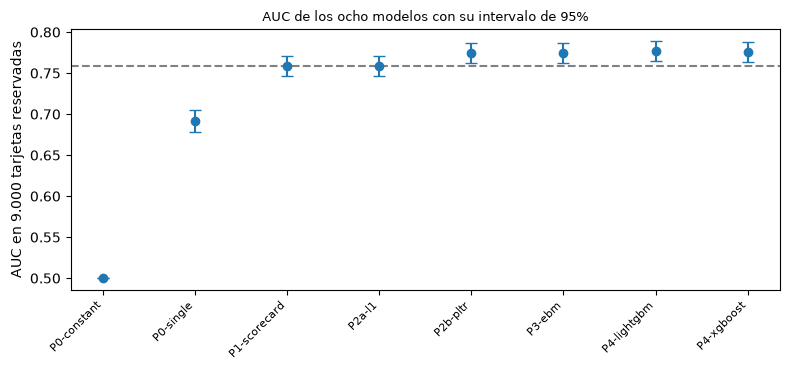

P0-constant AUC 0.5 DeLong p None
P0-single AUC 0.6917 DeLong p 1.26e-40
P1-scorecard AUC 0.7587 DeLong p None
P2a-l1 AUC 0.7587 DeLong p 0.0884
P2b-pltr AUC 0.7749 DeLong p 2.58e-11
P3-ebm AUC 0.7746 DeLong p 2.74e-10
P4-lightgbm AUC 0.777 DeLong p 6.53e-13
P4-xgboost AUC 0.7755 DeLong p 2.18e-12


In [5]:
# El AUC de los ocho modelos en las 9000 tarjetas reservadas con su intervalo de 95% versionado
auc_rows = {t["model_id"]: t for t in tests if t["test_id"] == "disc.auc"}
mid = [auc_rows[m]["metric"] for m in ladder]
low = [auc_rows[m]["metric"] - auc_rows[m]["extras"]["ci95_low"] for m in ladder]
high = [auc_rows[m]["extras"]["ci95_high"] - auc_rows[m]["metric"] for m in ladder]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(range(len(ladder)), mid, yerr=[low, high], fmt="o", capsize=4)
ax.axhline(auc_rows["P1-scorecard"]["metric"], color="gray", linestyle="--")
ax.set_xticks(range(len(ladder)), ladder, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("AUC en 9.000 tarjetas reservadas")
ax.set_title("AUC de los ocho modelos con su intervalo de 95%", fontsize=9)
fig.tight_layout()
plt.show()
for m in ladder:
    row = next((t for t in tests if t["test_id"] == "disc.delong" and t["model_id"] == m), None)
    p_value = None if row is None else float(f"{row['p_value']:.3g}")
    print(m, "AUC", round(auc_rows[m]["metric"], 4), "DeLong p", p_value)

La tarjeta de puntaje y la regresión logística penalizada empatan en 0,7587 (p de DeLong de 0,0884, sin diferencia), la línea base de una variable queda en 0,6917 (p de 1,26e-40), y los árboles penalizados, la máquina de refuerzo y los dos modelos de árboles potenciados llegan a 0,7746 hasta 0,777, cada uno distinto de la tarjeta de puntaje con valores p de 2,58e-11 a 6,53e-13. Los intervalos de los cinco modelos más ricos se traslapan todos con el de la tarjeta de puntaje, y sin embargo la prueba pareada los separa, porque los dos modelos puntúan las mismas tarjetas y sus errores están fuertemente correlacionados. Comparar intervalos es la prueba equivocada para una comparación pareada; la ganancia de cerca de 0,016 a 0,018 puntos de AUC es pequeña pero real.

### Paso 4: calibración, el nivel y el ajuste

La segunda familia pregunta si las PD tienen el tamaño correcto, y hace dos preguntas distintas. La prueba de **nivel** pregunta si la PD promedio es correcta: la prueba de Jeffreys (Brown, Cai y DasGupta, 2001) toma las tarjetas, los incumplimientos y la PD media y es de una cola, y rechaza solo cuando los incumplimientos exceden lo que admite la PD. Las pruebas de **ajuste** preguntan si la PD calza grupo por grupo: el chi cuadrado sobre los grados (BCBS, 2005) puede fallar aun cuando el promedio es correcto, porque una PD demasiado alta en algunos grados puede compensar otra demasiado baja en otros. La celda ejecuta la prueba de Jeffreys en cada uno de los ocho grados de la tarjeta de puntaje, el chi cuadrado sobre todos los grados y la prueba de semáforo, y dibuja el valor p de cada grado pintado con su luz.

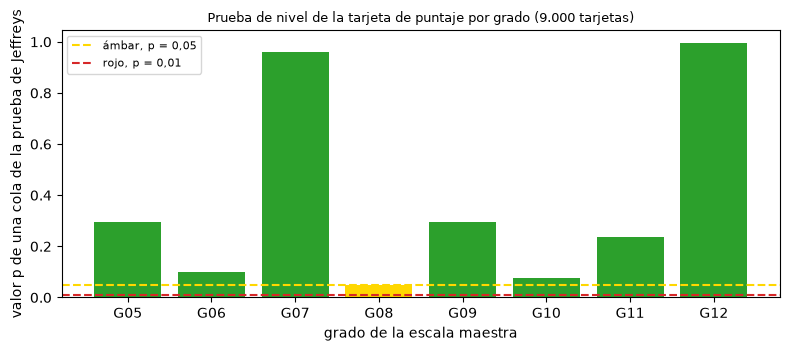

chi cuadrado sobre grados: p y luz: 0.0264 ámbar
nivel del portafolio, p de Jeffreys y luz: 0.3095 verde
colores del semáforo por grado: ['yellow', 'orange', 'green', 'red', 'yellow', 'orange', 'yellow', 'green']


In [6]:
# Jeffreys de una cola por grado, chi cuadrado sobre grados y semáforo de la tarjeta de puntaje, con el motor
grades = [g for g in rungs["P1-scorecard"]["grades"] if g["n"] > 0]
n_g, d_g, pd_g = [g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades]
names_g = [g["grade"] for g in grades]
per_grade = pd_jeffreys_grades(n_g, d_g, pd_g, grades=names_g, policy=policy, model_id="P1-scorecard")
chi = pd_chi2_grades(n_g, d_g, pd_g, policy=policy, model_id="P1-scorecard", segment="portfolio")
light = pd_traffic_lights(n_g, d_g, pd_g, policy=policy, model_id="P1-scorecard", segment="portfolio")
colors = {"green": "tab:green", "amber": "gold", "red": "tab:red", "not_evaluated": "lightgray"}
fig, ax = plt.subplots(figsize=(8, 3.6))
by_grade, portfolio = per_grade[:-1], per_grade[-1]
ax.bar(names_g, [r.p_value for r in by_grade], color=[colors[r.light.value] for r in by_grade])
ax.axhline(0.05, color="gold", linestyle="--", label="ámbar, p = 0,05")
ax.axhline(0.01, color="tab:red", linestyle="--", label="rojo, p = 0,01")
ax.set_xlabel("grado de la escala maestra")
ax.set_ylabel("valor p de una cola de la prueba de Jeffreys")
ax.set_title("Prueba de nivel de la tarjeta de puntaje por grado (9.000 tarjetas)", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("chi cuadrado sobre grados: p y luz:", round(chi.p_value, 4), LIGHT[chi.light.value])
print("nivel del portafolio, p de Jeffreys y luz:", round(portfolio.p_value, 4), LIGHT[portfolio.light.value])
print("colores del semáforo por grado:", light.extras["colours"])

El grado G08 es ámbar (p de 0,0494) y los demás son verdes, pero el nivel del portafolio tiene un p de Jeffreys de 0,3095 (verde): en promedio la PD no es demasiado baja. El ajuste es otra historia. El chi cuadrado sobre los grados es ámbar (p de 0,0264), y la prueba de semáforo pinta los grados de amarillo, naranja, verde, rojo, amarillo, naranja, amarillo y verde: el grado G08, el mayor, con 3.101 tarjetas, muestra más incumplimientos de los que admite su PD, y G12, el más riesgoso, menos. El portafolio acierta en promedio y se equivoca por grado de un modo que importa, y un validador que ejecutara solo la prueba de nivel no lo vería.

### Paso 5: Hosmer-Lemeshow, abierta

Hosmer-Lemeshow ordena las tarjetas por PD, las corta en $G$ grupos de igual tamaño y compara, en el grupo $g$ con $m_g$ tarjetas, los incumplimientos observados $O_g$ con los esperados $E_g$, la suma de las PD del grupo (Hosmer y Lemeshow, 1980):

$$\mathrm{HL} = \sum_{g=1}^{G} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g / m_g)}$$

con una referencia $\chi^2$ de $G$ grados de libertad cuando las PD se fijaron antes de los resultados, como en una muestra de validación. Los tramos de confiabilidad versionados son justamente tales grupos: diez tramos de 900 tarjetas, cada uno con su PD media y su tasa observada. La celda reconstruye 9.000 tarjetas desde ellos (la PD del tramo para cada tarjeta, el número observado de incumplimientos del tramo), llama a `pd_hosmer_lemeshow`, `pd_spiegelhalter`, `pd_brier` y `pd_ece` sobre la tarjeta de puntaje y sobre el modelo LightGBM monótono, y dibuja el diagrama de confiabilidad de cada uno.

P1-scorecard Hosmer-Lemeshow, p y luz: 0.015 ámbar
Spiegelhalter, p: 0.035
Brier y ECE de las tarjetas reconstruidas: 0.1404 0.0155
P4-lightgbm Hosmer-Lemeshow, p y luz: 0.008 roja
Spiegelhalter, p: 0.126
Brier y ECE de las tarjetas reconstruidas: 0.1376 0.0134


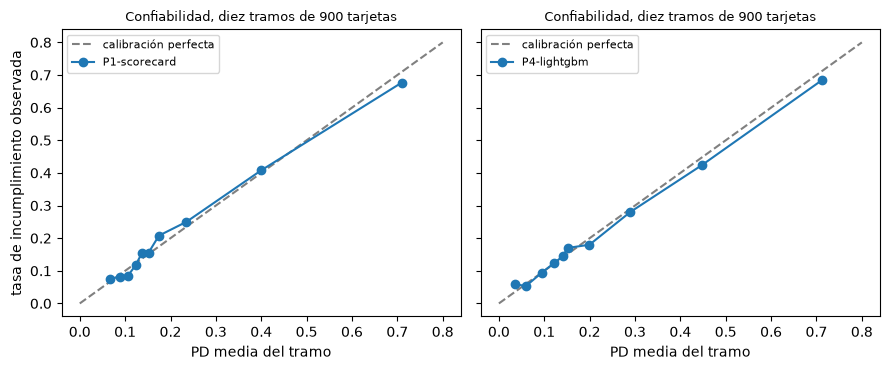

In [7]:
# Reconstruir 9000 tarjetas desde los tramos de confiabilidad y ejecutar Hosmer-Lemeshow, Spiegelhalter, Brier, ECE
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, rung in zip(axes, ("P1-scorecard", "P4-lightgbm")):
    bins_ = rungs[rung]["reliability"]
    pd_cards = np.concatenate([np.full(b["n"], b["pd"]) for b in bins_])
    hit = [int(round(b["dr"] * b["n"])) for b in bins_]
    flags = np.concatenate([np.r_[np.ones(h), np.zeros(b["n"] - h)] for b, h in zip(bins_, hit)])
    hl = pd_hosmer_lemeshow(flags, pd_cards, groups=10, policy=policy, model_id=rung, segment="portfolio")
    sp = pd_spiegelhalter(flags, pd_cards, policy=policy, model_id=rung, segment="portfolio")
    brier = pd_brier(flags, pd_cards, policy=policy, model_id=rung, segment="portfolio")
    ece = pd_ece(flags, pd_cards, policy=policy, model_id=rung, segment="portfolio")
    print(rung, "Hosmer-Lemeshow, p y luz:", round(hl.p_value, 4), LIGHT[hl.light.value])
    print("Spiegelhalter, p:", round(sp.p_value, 3))
    print("Brier y ECE de las tarjetas reconstruidas:", round(brier.metric, 4), round(ece.metric, 4))
    ax.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--", label="calibración perfecta")
    ax.plot([b["pd"] for b in bins_], [b["dr"] for b in bins_], marker="o", label=rung)
    ax.set_xlabel("PD media del tramo")
    ax.set_title("Confiabilidad, diez tramos de 900 tarjetas", fontsize=9)
    ax.legend(fontsize=8)
axes[0].set_ylabel("tasa de incumplimiento observada")
fig.tight_layout()
plt.show()

El motor devuelve un valor p de Hosmer-Lemeshow de 0,015 para la tarjeta de puntaje (ámbar), el valor versionado, y 0,008 para LightGBM (rojo): el mejor ordenador es el peor ajuste según esta prueba, lo que hace eco al chi cuadrado por grados del notebook 06. El puntaje de Brier de las tarjetas reconstruidas, 0,1404, queda algo sobre el 0,1393 versionado y el valor p de Spiegelhalter, 0,035, difiere del 0,0219 versionado, porque cada tarjeta de un tramo comparte una PD en el vector reconstruido y las PD reales varían dentro de un tramo; el ECE, 0,0155, y el estadístico de Hosmer-Lemeshow son funciones de las medias de los tramos y no sufren eso. Los diagramas muestran a ambos modelos cerca de la diagonal, con desviaciones en los tramos intermedios donde unos pocos cientos de incumplimientos deciden la prueba.

### Paso 6: estabilidad, la población frente al desarrollo

La tercera familia compara la población de ahora con la población en el desarrollo. El índice de estabilidad de la población (PSI) de la PD toma diez tramos fijados sobre las tarjetas de desarrollo (aquí las 16.800 tarjetas de entrenamiento) y compara la proporción de las tarjetas de la muestra reservada en cada uno, $\mathrm{PSI} = \sum_i (a_i - e_i)\ln(a_i/e_i)$ con $e_i$ y $a_i$ las proporciones en el desarrollo y ahora. Con un parámetro de referencia chi cuadrado (Yurdakul y Naranjo, 2020), el PSI tiene un valor crítico que depende solo de los dos tamaños de muestra y del número de tramos, que devuelve `psi_benchmark` del motor. La celda lo calcula para 16.800 tarjetas de desarrollo y 9.000 actuales, lo pone junto al PSI versionado de la tarjeta de puntaje, y dibuja la contribución de cada decil.

PSI de la tarjeta de puntaje y su valor crítico de 5%: 0.000952 0.00289
valor crítico versionado por la cadena de cálculo: 0.00289


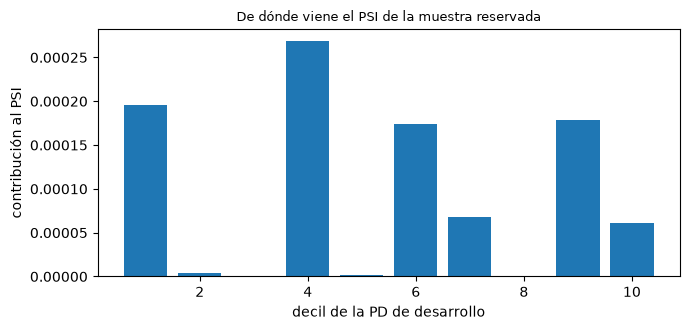

In [8]:
# El PSI crítico del motor para estos tamaños, frente al PSI de la tarjeta de puntaje y sus contribuciones por decil
psi_row = next(t for t in tests if t["test_id"] == "stability.psi" and t["model_id"] == "P1-scorecard")
extras = psi_row["extras"]
critical = psi_benchmark(extras["n"], extras["m"], extras["bins"])
print("PSI de la tarjeta de puntaje y su valor crítico de 5%:", round(psi_row["metric"], 6), round(critical, 5))
print("valor crítico versionado por la cadena de cálculo:", round(extras["benchmark_05"], 5))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(1, len(extras["contributions"]) + 1), extras["contributions"], color="tab:blue")
ax.set_xlabel("decil de la PD de desarrollo")
ax.set_ylabel("contribución al PSI")
ax.set_title("De dónde viene el PSI de la muestra reservada", fontsize=9)
fig.tight_layout()
plt.show()

El PSI de la tarjeta de puntaje, 0,000952, es un tercio del valor crítico de 0,00289 que el motor calcula desde los tamaños de muestra, el mismo 0,00289 que versionó la cadena de cálculo: la muestra reservada tiene la población del desarrollo, como debe ser, pues la división fue estratificada. Las contribuciones son minúsculas en todos los deciles, la mayor en el cuarto, cerca de 0,0003. Un PSI tan pequeño dice que no hay deriva que ver, lo que hace informativo el paso siguiente: pregunta qué dicen las mismas pruebas cuando la hay.

### Paso 7: qué nota cada prueba cuando cambian las tarjetas

La misma tarjeta de puntaje enfrenta tres conjuntos de evaluación: la muestra reservada tal como es, la muestra reservada con una deriva moderada de las entradas, y la muestra reservada con la tasa de incumplimiento multiplicada por 1,5 (2.986 incumplimientos en lugar de 1.991). Los modelos no se reajustan. Una batería es útil solo si sus pruebas notan cosas distintas, y esta comparación es la evidencia de cuál nota qué. La celda llama a la prueba de nivel del motor, `pd_jeffreys`, sobre cada conjunto desde las tarjetas, los incumplimientos y la PD media versionados, imprime los valores p versionados de seis pruebas, y los dibuja en escala logarítmica con la línea de 5%.

p de Jeffreys de la tarjeta de puntaje por conjunto de evaluación: [0.31, 0.728, 8.67e-79]
disc.auc_vs_initial [0.226, 0.938, 0.558]
pd.jeffreys [0.31, 0.728, 8.67e-79]
pd.binomial_vasicek [0.454, 0.493, 0.09]
pd.hosmer_lemeshow [0.015, 0.00163, 2.19e-109]
pd.spiegelhalter [0.0219, 0.0115, 6.45e-65]
stability.psi [0.781, 3.35e-36, 2.31e-14]


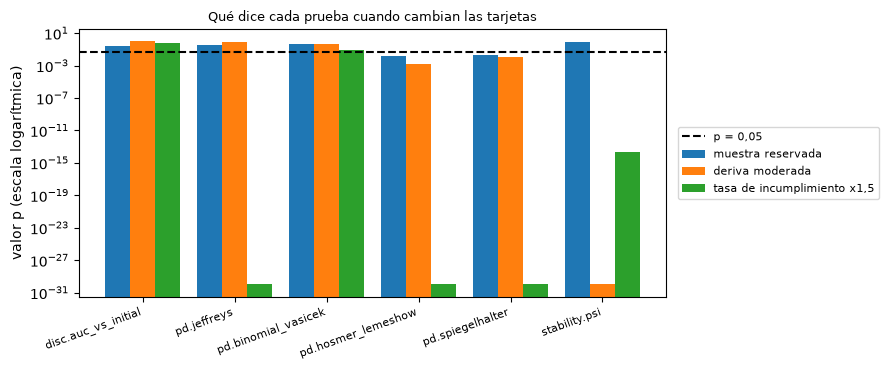

In [9]:
# La prueba de nivel del motor sobre la tarjeta de puntaje en cada conjunto de evaluación y las filas versionadas
sets = (holdout, drift, prior)
show = ["disc.auc_vs_initial", "pd.jeffreys", "pd.binomial_vasicek"]
show += ["pd.hosmer_lemeshow", "pd.spiegelhalter", "stability.psi"]
jef = []
for doc in sets:
    bins_ = doc["outputs"]["rungs"]["P1-scorecard"]["reliability"]
    n_all, d_all = doc["outputs"]["n"], doc["outputs"]["defaults"]
    mean_pd = sum(b["n"] * b["pd"] for b in bins_) / sum(b["n"] for b in bins_)
    kw = dict(policy=policy, model_id="P1-scorecard", segment="portfolio")
    jef.append(pd_jeffreys(n_all, d_all, mean_pd, **kw).p_value)
print("p de Jeffreys de la tarjeta de puntaje por conjunto de evaluación:", [float(f"{p:.3g}") for p in jef])
committed = {}
for i in show:
    rows = [t for doc in sets for t in doc["tests"] if t["test_id"] == i and t["model_id"] == "P1-scorecard"]
    committed[i] = [t["p_value"] for t in rows if t["segment"] == "portfolio"]
    print(i, [float(f"{p:.3g}") for p in committed[i]])
width = 0.27
fig, ax = plt.subplots(figsize=(9, 3.8))
for j, name in enumerate(["muestra reservada", "deriva moderada", "tasa de incumplimiento x1,5"]):
    values = [committed[i][j] for i in show]
    ax.bar(np.arange(len(show)) + (j - 1) * width, np.maximum(values, 1e-30), width=width, label=name)
ax.set_yscale("log")
ax.axhline(0.05, color="black", linestyle="--", label="p = 0,05")
ax.set_xticks(range(len(show)), show, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("valor p (escala logarítmica)")
ax.set_title("Qué dice cada prueba cuando cambian las tarjetas", fontsize=9)
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

## Resultados

**Respuesta:** Cada familia nota un problema distinto, y ninguna los nota todos. La batería tiene 187 filas, 11 de 15 pruebas con umbral; la familia del AUC dice que los modelos más ricos ordenan mejor (p de DeLong de 2,58e-11 para los árboles penalizados, 6,53e-13 para LightGBM) con un AUC de 0,7587 para la tarjeta de puntaje. La familia de nivel guarda silencio ante una deriva de las entradas y grita ante un cambio de la tasa de incumplimiento: el valor p de Jeffreys de la tarjeta de puntaje es 0,31 en la muestra reservada, 0,728 bajo la deriva moderada y 8,67e-79 cuando la tasa de incumplimiento sube en la mitad. Las pruebas de ajuste sí ven la deriva: Hosmer-Lemeshow da 0,015 en la muestra reservada (ámbar, el valor que devuelve el motor desde los diez tramos de confiabilidad) y 0,00163 bajo la deriva, y el PSI pasa de 0,781 a 3,35e-36, frente a un valor crítico de 0,00289 en la muestra reservada. El chi cuadrado sobre los grados de la tarjeta de puntaje es ámbar (0,0264) mientras su nivel de portafolio es verde (0,3095).

Un modelo puede entonces estar en verde en una familia y en ámbar o rojo en otra, por una razón: la tarjeta de puntaje ordena tan bien como acierta su nivel en promedio, y sus grados calzan menos; LightGBM ordena mejor y calza peor (p de Hosmer-Lemeshow de 0,008). La figura del último paso lo muestra con claridad: las barras de las pruebas de nivel caen solo en el último grupo, mientras las de ajuste y estabilidad caen en ambos.

Lo que este notebook no muestra: las filas de estabilidad por característica (20 variables, todas verdes en la muestra reservada), las luces de los otros siete modelos en cada familia, y nada sobre el orden en el tiempo de las tarjetas, pues C01 es una sola fotografía de 2005: la pregunta fuera de tiempo es el notebook 04.

## Resumen

- Una batería, 15 pruebas, ocho modelos: las filas de portafolio llevan el titular, las de grado ubican el problema, las de característica vigilan las entradas; las filas descriptivas (AUC, KS, Brier, ECE) nunca encienden una luz.
- Discriminación, nivel, ajuste y estabilidad son familias separadas. Una prueba de DeLong pareada, no los intervalos traslapados, dice si un retador ordena mejor, y una prueba de nivel no puede ver un desajuste por grado.
- El motor reproduce una fila versionada desde los números que guarda el artefacto: Hosmer-Lemeshow desde diez tramos de confiabilidad, el PSI crítico desde los dos tamaños de muestra, las filas de Jeffreys por grado y de portafolio.
- Los conjuntos de evaluación desplazados muestran que las pruebas notan cosas distintas: una deriva de las entradas llega al PSI y a las pruebas de ajuste, un cambio de la tasa de incumplimiento llega a las pruebas de nivel, y el AUC contra desarrollo no nota ninguno.

**Qué probar a continuación.** Reemplaza `P4-lightgbm` por `P3-ebm` en el paso 5 y compara el valor p de Hosmer-Lemeshow; luego continúa con el notebook 04, que aplica la misma disciplina fuera de tiempo, sobre los créditos de pequeñas empresas del caso C03.

## Referencias

- DeLong, E. R., DeLong, D. M. y Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves: a nonparametric approach, Biometrics 44(3). https://doi.org/10.2307/2531595
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revisado): la binomial, la binomial ajustada por Vasicek y el chi-cuadrado sobre grados. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 y 2.5.4.1 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients